# **Analisi esplorativa di `additional_truths.arff`**

In questo notebook viene effettuata l'analisi esplorativa del dataset `additional_truths.arff`.

Prima di procedere con il caricamento e l'analisi tramite Pandas, viene esaminata la struttura originale del file ARFF per comprenderne l'organizzazione, gli attributi presenti e la rappresentazione dei dati.

In [3]:

from pathlib import Path

# Current directory
current = Path.cwd()

# Repository root
project_root = current.parent

# Shared project folder
base_dir = project_root.parent

# ARFF dataset path
arff_path = (
    base_dir
    / "code_project"
    / "data"
    / "Additional_Data"
    / "additional_truths.arff"
)

print("ARFF path:", arff_path)
print("File exists:", arff_path.is_file())




ARFF path: c:\Users\bucco\Desktop\Laboratory of Data Science\project\code_project\data\Additional_Data\additional_truths.arff
File exists: True


### Struttura del file ARFF


La relazione è denominata `trump_truths` e presenta 10 attributi: `id`, `timestamp`, `text`, `url`, `reply_count`, `retruth_count`, `like_count`, `external_id`, `author` e `time_scraped`.


In [ ]:
#author è sempre 27

In [4]:

record_count = 0
data_started = False

with open(arff_path, "r", encoding="utf-8") as file:
    for line in file:
        line = line.strip()

        if line.lower() == "@data":
            data_started = True
            continue

        if data_started and line and not line.startswith("%"):
            record_count += 1

print("Numero di record:", record_count)


Numero di record: 35222


Pandas

In [6]:
#Prendi i primi 2 campi partendo da sinistra e gli ultimi 7 partendo da destra.
#Tutto quello che rimane in mezzo è il text. (che crea problemi nel capire se ogni riga ha gli stessi campi)
import pandas as pd

columns = [
    "id", "timestamp", "text", "url",
    "reply_count", "retruth_count", "like_count",
    "external_id", "author", "time_scraped"
]

records = []
data_started = False #serve a ignorare l'header

with open(arff_path, "r", encoding="utf-8") as file:
    for line in file:
        line = line.strip() #strip() elimina spazi e soprattutto il carattere di fine riga \n all’inizio/fine.

        if line.lower() == "@data":
            data_started = True
            continue

        if data_started and line:
            # I primi due campi vengono separati da sinistra
            left = line.split(",", 2)

            # Gli ultimi sette campi vengono separati da destra
            text_and_right = left[2].rsplit(",", 7)

            row = [left[0], left[1]] + text_and_right
            records.append(row)

df_additional = pd.DataFrame(records, columns=columns)

print("Dimensioni del dataset:", df_additional.shape)
display(df_additional.head())

Dimensioni del dataset: (35222, 10)


,id,timestamp,text,url,reply_count,retruth_count,like_count,external_id,author,time_scraped
0,117323511508375196,'2026-09-24 01:51:54','','https://truthsocial.com/@realDonaldTrump/1173...,792.0,1849.0,7259.0,'117323511508375196',27.0,'2026-09-20 14:00:00.000000'
1,117323155721195611,'2026-09-24 00:21:25',"""The story that the White House, or me, want t...",'https://truthsocial.com/@realDonaldTrump/1173...,1329.0,3534.0,12560.0,'117323155721195611',27.0,'2026-09-20 14:00:00.000000'
2,117323148147220269,'2026-09-24 00:19:29','BIG DAY FOR BOEING AND AMERICAN MANUFACTURING...,'https://truthsocial.com/@realDonaldTrump/1173...,510.0,2714.0,10677.0,'117323148147220269',27.0,'2026-09-20 14:00:00.000000'
3,117322092055919832,'2026-09-23 19:50:55','','https://truthsocial.com/@realDonaldTrump/1173...,1344.0,2740.0,11287.0,'117322092055919832',27.0,'2026-09-20 14:00:00.000000'
4,117322065119445871,'2026-09-23 19:44:04',"'The Great Gary Player, Bryson DeChambeau, Mik...",'https://truthsocial.com/@realDonaldTrump/1173...,505.0,2156.0,10284.0,'117322065119445871',27.0,'2026-09-20 14:00:00.000000'


### Struttura del DataFrame e valori mancanti


In [ ]:
df_additional.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35222 entries, 0 to 35221
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id             35222 non-null  object
 1   timestamp      35222 non-null  object
 2   text           35222 non-null  object
 3   url            35222 non-null  object
 4   reply_count    35222 non-null  object
 5   retruth_count  35222 non-null  object
 6   like_count     35222 non-null  object
 7   external_id    35222 non-null  object
 8   author         35222 non-null  object
 9   time_scraped   35222 non-null  object
dtypes: object(10)
memory usage: 2.7+ MB


#### Verifica dei valori vuoti


In [7]:
for column in df_additional.columns:
    print(column, ":", (df_additional[column].str.strip() == "").sum())

id : 0
timestamp : 0
text : 0
url : 0
reply_count : 0
retruth_count : 0
like_count : 0
external_id : 0
author : 0
time_scraped : 0


In [ ]:
#not working

In [8]:
def remove_quotes(value):
    value = value.strip()

    if len(value) >= 2:
        if (value[0] == "'" and value[-1] == "'") or \
           (value[0] == '"' and value[-1] == '"'):
            return value[1:-1]

    return value

In [9]:
df_additional = pd.DataFrame(records, columns=columns)

In [10]:
for column in df_additional.columns:
    df_additional[column] = df_additional[column].apply(remove_quotes)

In [11]:
for column in df_additional.columns:
    print(column, ":", (df_additional[column].str.strip() == "").sum())

id : 0
timestamp : 0
text : 7262
url : 0
reply_count : 0
retruth_count : 0
like_count : 0
external_id : 0
author : 0
time_scraped : 0


#### Conversione dei tipi di dato

Poiché il DataFrame è stato costruito a partire dalla lettura testuale del file ARFF, Pandas ha inizialmente rappresentato tutti gli attributi come `object`.

In [12]:
df_additional["id"] = pd.to_numeric(df_additional["id"])

numeric_columns = [
    "reply_count",
    "retruth_count",
    "like_count",
    "author"
]

for column in numeric_columns:
    df_additional[column] = pd.to_numeric(df_additional[column])

ValueError: Unable to parse string 'nan' at position 10943

In [ ]:
#non funziona per via dei "nan"

In [13]:
for column in ["reply_count", "retruth_count", "like_count", "author"]:
    print(column, ":", (df_additional[column].str.lower() == "nan").sum())

reply_count : 9
retruth_count : 9
like_count : 9
author : 0


In [14]:
nan_engagement = df_additional[
    (df_additional["reply_count"].str.lower() == "nan") |
    (df_additional["retruth_count"].str.lower() == "nan") |
    (df_additional["like_count"].str.lower() == "nan")
]

display(nan_engagement)

,id,timestamp,text,url,reply_count,retruth_count,like_count,external_id,author,time_scraped
10943,114135887529701366,2025-03-10 02:57:12,"Malcolm Turnbull, the former Prime Minister of...",https://truthsocial.com/@realDonaldTrump/11413...,nan,nan,nan,114135887529701366,27.0,2026-09-20 14:00:00.000000
10944,114135672415463032,2025-03-10 02:02:29,Great job by Congressman Brian Mast on FoxNews...,https://truthsocial.com/@realDonaldTrump/11413...,nan,nan,nan,114135672415463032,27.0,2026-09-20 14:00:00.000000
10945,114135406628804244,2025-03-10 00:54:54,"We're going to become so rich, you're not gonn...",https://truthsocial.com/@realDonaldTrump/11413...,nan,nan,nan,114135406628804244,27.0,2026-09-20 14:00:00.000000
10946,114135400416790297,2025-03-10 00:53:19,Democrats are out of control—They've lost thei...,https://truthsocial.com/@realDonaldTrump/11413...,nan,nan,nan,114135400416790297,27.0,2026-09-20 14:00:00.000000
10947,114135394676135924,2025-03-10 00:51:51,I want a dynamic Country where private enterpr...,https://truthsocial.com/@realDonaldTrump/11413...,nan,nan,nan,114135394676135924,27.0,2026-09-20 14:00:00.000000
10948,114135388919019484,2025-03-10 00:50:24,Nobody has been tougher on Russia than Donald ...,https://truthsocial.com/@realDonaldTrump/11413...,nan,nan,nan,114135388919019484,27.0,2026-09-20 14:00:00.000000
10949,114135383571986279,2025-03-10 00:49:02,The Carter Administration gave the Panama Cana...,https://truthsocial.com/@realDonaldTrump/11413...,nan,nan,nan,114135383571986279,27.0,2026-09-20 14:00:00.000000
10950,114135377964485025,2025-03-10 00:47:36,I’m not going to touch Social Security—We’re g...,https://truthsocial.com/@realDonaldTrump/11413...,nan,nan,nan,114135377964485025,27.0,2026-09-20 14:00:00.000000
10951,114135068157531979,2025-03-09 23:28:49,As I made clear during my Joint Address to Con...,https://truthsocial.com/@realDonaldTrump/11413...,nan,nan,nan,114135068157531979,27.0,2026-09-20 14:00:00.000000


sono gli stessi 9 record

In [15]:
#conversione
numeric_columns = [
    "reply_count",
    "retruth_count",
    "like_count",
    "author"
]

for column in numeric_columns:
    df_additional[column] = pd.to_numeric(
        df_additional[column],
        errors="coerce"
    )

In [16]:
df_additional.dtypes

id                 int64
timestamp            str
text                 str
url                  str
reply_count      float64
retruth_count    float64
like_count       float64
external_id          str
author           float64
time_scraped         str
dtype: object

In [17]:
df_additional[numeric_columns].isna().sum()

reply_count      9
retruth_count    9
like_count       9
author           0
dtype: int64

### Analisi dei valori mancanti

considerando sia i valori `NaN` riconosciuti da Pandas sia le stringhe vuote presenti negli attributi testuali.

In [18]:
missing_values = {}

for column in df_additional.columns:
    nan_count = df_additional[column].isna().sum()

    if df_additional[column].dtype == "object":
        empty_count = (df_additional[column].str.strip() == "").sum()
    else:
        empty_count = 0

    missing_values[column] = nan_count + empty_count

missing_values = pd.Series(missing_values)

print(missing_values)
print("\nTotale valori mancanti:", missing_values.sum())

id               0
timestamp        0
text             0
url              0
reply_count      9
retruth_count    9
like_count       9
external_id      0
author           0
time_scraped     0
dtype: int64

Totale valori mancanti: 27


### Analisi degli identificativi

`id` ed `external_id`

In [19]:
print("Record totali:", len(df_additional))

print("\nID distinti:", df_additional["id"].nunique())
print("ID duplicati:", df_additional["id"].duplicated().sum())

print("\nExternal ID distinti:", df_additional["external_id"].nunique())
print("External ID duplicati:", df_additional["external_id"].duplicated().sum())

Record totali: 35222

ID distinti: 35222
ID duplicati: 0

External ID distinti: 35222
External ID duplicati: 0


Non sono quindi presenti identificativi duplicati ed entrambi gli attributi risultano univoci all'interno del dataset.

#### Confronto tra `id` ed `external_id`


In [20]:
same_id = (
    df_additional["id"].astype(str) == df_additional["external_id"]
)

print("Record con ID uguali:", same_id.sum())
print("Record con ID diversi:", (~same_id).sum())

Record con ID uguali: 35222
Record con ID diversi: 0


I due attributi risultano quindi ridondanti

### Analisi degli attributi temporali


In [21]:
timestamp_dt = pd.to_datetime(
    df_additional["timestamp"],
    errors="coerce"
)

time_scraped_dt = pd.to_datetime(
    df_additional["time_scraped"],
    errors="coerce"
)

print("Timestamp non convertibili:", timestamp_dt.isna().sum())
print("Time scraped non convertibili:", time_scraped_dt.isna().sum())

Timestamp non convertibili: 0
Time scraped non convertibili: 0


In [22]:
print("Timestamp minimo:", timestamp_dt.min())
print("Timestamp massimo:", timestamp_dt.max())

print("\nTime scraped minimo:", time_scraped_dt.min())
print("Time scraped massimo:", time_scraped_dt.max())

Timestamp minimo: 2022-04-28 21:29:28
Timestamp massimo: 2026-09-24 01:51:54

Time scraped minimo: 2026-09-20 14:00:00
Time scraped massimo: 2026-09-20 14:00:00


In [23]:
posts_after_scrape = timestamp_dt > time_scraped_dt

print(
    "Post con timestamp successivo a time_scraped:",
    posts_after_scrape.sum()
)

Post con timestamp successivo a time_scraped: 42


In [24]:
display(
    df_additional.loc[
        posts_after_scrape,
        ["id", "timestamp", "time_scraped"]
    ]
)

,id,timestamp,time_scraped
0,117323511508375196,2026-09-24 01:51:54,2026-09-20 14:00:00.000000
1,117323155721195611,2026-09-24 00:21:25,2026-09-20 14:00:00.000000
2,117323148147220269,2026-09-24 00:19:29,2026-09-20 14:00:00.000000
3,117322092055919832,2026-09-23 19:50:55,2026-09-20 14:00:00.000000
4,117322065119445871,2026-09-23 19:44:04,2026-09-20 14:00:00.000000
5,117320581360547091,2026-09-23 13:26:43,2026-09-20 14:00:00.000000
6,117320509296515188,2026-09-23 13:08:24,2026-09-20 14:00:00.000000
7,117320385350427395,2026-09-23 12:36:52,2026-09-20 14:00:00.000000
8,117318371569831036,2026-09-23 04:04:44,2026-09-20 14:00:00.000000
9,117318370203435194,2026-09-23 04:04:24,2026-09-20 14:00:00.000000


sono stati individuati **42 record** nei quali il `timestamp` di pubblicazione è successivo al valore di `time_scraped`. 

### Analisi dell'attributo `author`



In [25]:
print("Autori distinti:", df_additional["author"].nunique())

print("\nFrequenza degli autori:")
display(df_additional["author"].value_counts().head(10))

Autori distinti: 1

Frequenza degli autori:


author
27.0    35222
Name: count, dtype: int64

l'attributo `author` assume un unico valore, pari a `27`. `additional_truths.arff` contiene quindi esclusivamente post associati allo stesso autore.

### Analisi degli attributi di engagement


In [26]:
engagement_columns = [
    "reply_count",
    "retruth_count",
    "like_count"
]

df_additional[engagement_columns].describe().round(2)

,reply_count,retruth_count,like_count
count,35213.00,35213.00,35213.00
mean,798.93,3273.24,12890.84
std,1351.25,2966.21,11553.46
min,0.00,0.00,0.00
25%,125.00,1460.00,5697.00
50%,398.00,2808.00,11136.00
75%,988.00,4482.00,17596.00
max,60886.00,123196.00,410837.00


### Analisi dei valori massimi di engagement


In [27]:
for column in engagement_columns:
    print("\nMassimo", column, ":", df_additional[column].max())
    
    display(
        df_additional.loc[
            df_additional[column] == df_additional[column].max(),
            ["id", "timestamp", "text", column]
        ]
    )


Massimo reply_count : 60886.0


,id,timestamp,text,reply_count
35221,108211822140637685,2022-04-28 21:29:28,I’M BACK! #COVFEFE,60886.0



Massimo retruth_count : 123196.0


,id,timestamp,text,retruth_count
35221,108211822140637685,2022-04-28 21:29:28,I’M BACK! #COVFEFE,123196.0



Massimo like_count : 410837.0


,id,timestamp,text,like_count
35221,108211822140637685,2022-04-28 21:29:28,I’M BACK! #COVFEFE,410837.0


i valori massimi dei tre attributi di engagement appartengono allo stesso record, relativo al post "I’M BACK! #COVFEFE"

### Analisi dei record duplicati



In [28]:
duplicated_rows = df_additional.duplicated().sum()

print("Record completamente duplicati:", duplicated_rows)

Record completamente duplicati: 0


### Analisi dell'attributo `text`


In [29]:
empty_text = df_additional["text"].str.strip() == ""

display(
    df_additional.loc[
        empty_text,
        ["id", "timestamp", "text", "url",
         "reply_count", "retruth_count", "like_count"]
    ].head(10)
)

,id,timestamp,text,url,reply_count,retruth_count,like_count
0,117323511508375196,2026-09-24 01:51:54,,https://truthsocial.com/@realDonaldTrump/11732...,792.0,1849.0,7259.0
3,117322092055919832,2026-09-23 19:50:55,,https://truthsocial.com/@realDonaldTrump/11732...,1344.0,2740.0,11287.0
11,117318365806497574,2026-09-23 04:03:16,,https://truthsocial.com/@realDonaldTrump/11731...,1197.0,3686.0,14111.0
37,117305526182125195,2026-09-20 21:37:59,,https://truthsocial.com/@realDonaldTrump/11730...,1490.0,3425.0,15092.0
38,117305110887067544,2026-09-20 19:52:22,,https://truthsocial.com/@realDonaldTrump/11730...,1424.0,3640.0,14039.0
39,117305110118463243,2026-09-20 19:52:11,,https://truthsocial.com/@realDonaldTrump/11730...,839.0,3830.0,13683.0
40,117305109272193640,2026-09-20 19:51:58,,https://truthsocial.com/@realDonaldTrump/11730...,506.0,3335.0,12919.0
41,117304284426928910,2026-09-20 16:22:12,,https://truthsocial.com/@realDonaldTrump/11730...,2276.0,5741.0,22903.0
42,117303611907345909,2026-09-20 13:31:10,,https://truthsocial.com/@realDonaldTrump/11730...,1037.0,4002.0,15345.0
46,117298879209243512,2026-09-19 17:27:35,,https://truthsocial.com/@realDonaldTrump/11729...,2330.0,6511.0,27636.0


### Analisi dell'attributo `url`


In [30]:
expected_prefix = "https://truthsocial.com/@realDonaldTrump/"

valid_url = df_additional["url"].str.startswith(expected_prefix)

print("URL con struttura attesa:", valid_url.sum())
print("URL con struttura diversa:", (~valid_url).sum())

URL con struttura attesa: 35222
URL con struttura diversa: 0


tutti i 35.522 record presentano un URL che inizia con `https://truthsocial.com/@realDonaldTrump/`.

### Coerenza tra `url` e identificativo del post


In [31]:
url_ends_with_id = df_additional.apply(
    lambda row: row["url"].endswith("/" + str(row["id"])),
    axis=1
)

print("URL coerenti con id:", url_ends_with_id.sum())
print("URL non coerenti con id:", (~url_ends_with_id).sum())

URL coerenti con id: 35222
URL non coerenti con id: 0


### Distribuzione temporale dei post


In [32]:
posts_per_year = timestamp_dt.dt.year.value_counts().sort_index()

display(posts_per_year)

timestamp
2022     2707
2023     9905
2024    10587
2025     6229
2026     5794
Name: count, dtype: int64

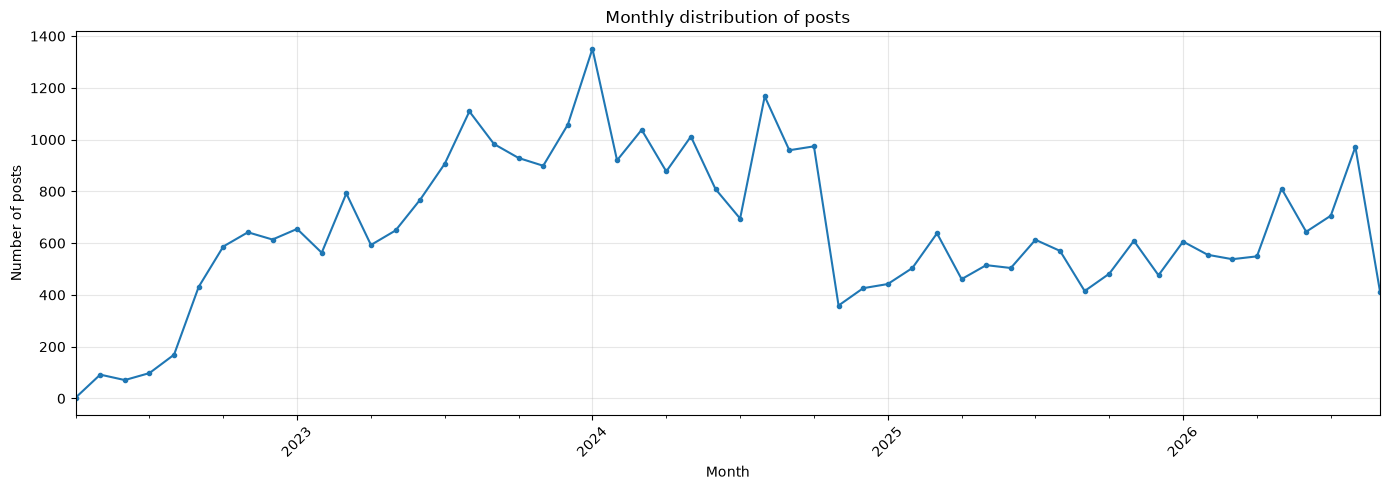

Month with most posts: 2024-01
Maximum number of posts: 1351


In [33]:

import matplotlib.pyplot as plt

posts_per_month = (
    timestamp_dt.dt.to_period("M")
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(14, 5))
posts_per_month.plot(kind="line", marker="o", markersize=3)

plt.title("Monthly distribution of posts")
plt.xlabel("Month")
plt.ylabel("Number of posts")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Month with most posts:", posts_per_month.idxmax())
print("Maximum number of posts:", posts_per_month.max())


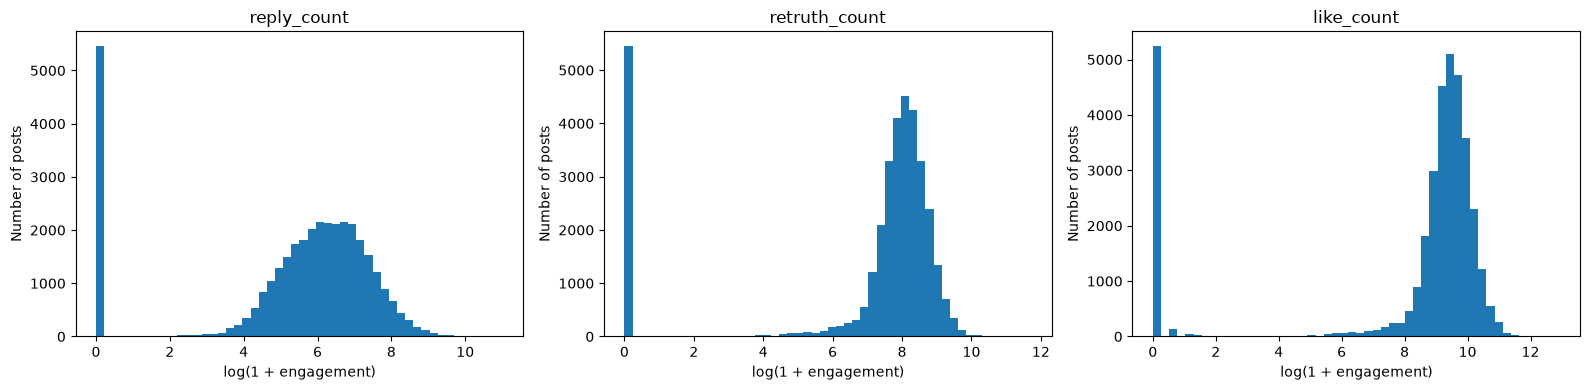


reply_count
Median: 398.0
99th percentile: 5945.639999999992
Upper IQR bound: 2282.5
Potential outliers: 2628

retruth_count
Median: 2808.0
99th percentile: 13136.399999999987
Upper IQR bound: 9015.0
Potential outliers: 1397

like_count
Median: 11136.0
99th percentile: 52177.799999999974
Upper IQR bound: 35444.5
Potential outliers: 1389


In [34]:

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, column in zip(axes, engagement_columns):
    values = df_additional[column].dropna()

    ax.hist(np.log1p(values), bins=50)
    ax.set_title(column)
    ax.set_xlabel("log(1 + engagement)")
    ax.set_ylabel("Number of posts")

plt.tight_layout()
plt.show()

for column in engagement_columns:
    values = df_additional[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    upper_bound = q3 + 1.5 * iqr
    outliers = (values > upper_bound).sum()

    print(f"\n{column}")
    print("Median:", values.median())
    print("99th percentile:", values.quantile(0.99))
    print("Upper IQR bound:", upper_bound)
    print("Potential outliers:", outliers)


In [35]:

texts = df_additional["text"].fillna("").str.strip()

# Escludiamo i testi vuoti
non_empty_texts = texts[texts != ""]

text_frequencies = non_empty_texts.value_counts()

repeated_texts = text_frequencies[
    text_frequencies > 1
]

print("Distinct repeated texts:", len(repeated_texts))
print("Posts with repeated text:", repeated_texts.sum())

display(repeated_texts.head(10))


Distinct repeated texts: 982
Posts with repeated text: 3295


text
RT @realDonaldTrump             271
https://www.DonaldJTrump.com    204
RT @GodandCountryy               76
MAKE AMERICA GREAT AGAIN!        56
RT @OksanaTrump                  51
RT @FruitSnacks                  36
RT @akaPR0B0SS                   35
RT @TheRealTrumpSupporters       29
RT @SpiritualStreetfighter       27
RT @IStandWithTrump47            25
Name: count, dtype: int64

Text length statistics:


count    35222.000000
mean       208.487508
std        293.780428
min          0.000000
25%         25.000000
50%        109.000000
75%        258.000000
max       4279.000000
Name: text_length, dtype: float64


Spearman correlations:


,text_length,reply_count,retruth_count,like_count
text_length,1.000000,0.089839,0.086384,0.075234
reply_count,0.089839,1.000000,0.917010,0.897593
retruth_count,0.086384,0.917010,1.000000,0.971729
like_count,0.075234,0.897593,0.971729,1.000000


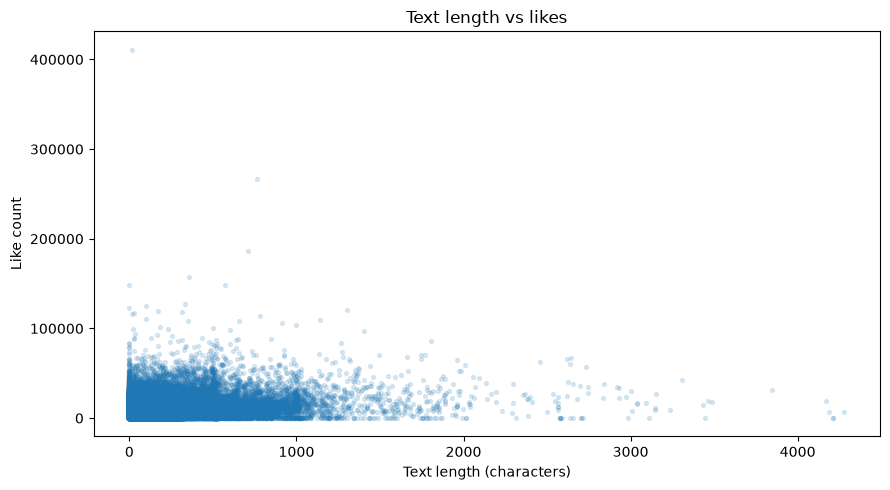

In [36]:

import matplotlib.pyplot as plt

analysis_df = df_additional.copy()

analysis_df["text_length"] = (
    analysis_df["text"].fillna("").str.len()
)

print("Text length statistics:")
display(analysis_df["text_length"].describe())

print("\nSpearman correlations:")
display(
    analysis_df[
        ["text_length"] + engagement_columns
    ].corr(method="spearman")
)

plt.figure(figsize=(9, 5))

plt.scatter(
    analysis_df["text_length"],
    analysis_df["like_count"],
    alpha=0.15,
    s=8
)

plt.xlabel("Text length (characters)")
plt.ylabel("Like count")
plt.title("Text length vs likes")
plt.tight_layout()
plt.show()


## Comparison with the main Truths dataset

This section compares `additional_truths.arff` with the main
`truths.csv` dataset to identify overlapping records, additional
posts, and potential inconsistencies between the two sources.

In [37]:

import pandas as pd
from pathlib import Path

# Locate the main truths.csv dataset
possible_paths = [
    Path("../Project_Data/truths.csv"),
    Path("../../code_project/data/Project_Data/truths.csv"),
    Path("../../code_project/data/truths.csv")
]

truths_path = next(
    (p for p in possible_paths if p.is_file()),
    None
)

if truths_path is None:
    raise FileNotFoundError(
        "truths.csv not found. Check the dataset location."
    )

# Load the main dataset
df_truths = pd.read_csv(
    truths_path,
    low_memory=False
)

print("Main truths dataset:", df_truths.shape)
print("Additional truths dataset:", df_additional.shape)

print("\nMain dataset columns:")
print(df_truths.columns.tolist())

print("\nAdditional dataset columns:")
print(df_additional.columns.tolist())


Main truths dataset: (1051149, 13)
Additional truths dataset: (35222, 10)

Main dataset columns:
['id', 'timestamp', 'time_scraped', 'is_retruth', 'is_reply', 'author', 'like_count', 'retruth_count', 'reply_count', 'text', 'external_id', 'url', 'truth_retruthed']

Additional dataset columns:
['id', 'timestamp', 'text', 'url', 'reply_count', 'retruth_count', 'like_count', 'external_id', 'author', 'time_scraped']


In [38]:

# Convert identifiers to a common string representation
main_ids = (
    df_truths["id"]
    .astype("string")
    .str.strip()
)

additional_ids = (
    df_additional["id"]
    .astype("string")
    .str.strip()
)

print("Main dataset unique IDs:", main_ids.nunique())
print("Additional dataset unique IDs:", additional_ids.nunique())

print("\nMain dataset missing IDs:", main_ids.isna().sum())
print("Additional dataset missing IDs:", additional_ids.isna().sum())

print("\nMain dataset duplicated IDs:", main_ids.duplicated().sum())
print("Additional dataset duplicated IDs:", additional_ids.duplicated().sum())


Main dataset unique IDs: 1038821
Additional dataset unique IDs: 35222

Main dataset missing IDs: 0
Additional dataset missing IDs: 0

Main dataset duplicated IDs: 12328
Additional dataset duplicated IDs: 0


In [39]:

# Identify overlapping and exclusive posts
main_id_set = set(main_ids.dropna())
additional_id_set = set(additional_ids.dropna())

common_ids = main_id_set & additional_id_set
only_main_ids = main_id_set - additional_id_set
only_additional_ids = additional_id_set - main_id_set

comparison = pd.DataFrame({
    "Category": [
        "Common posts",
        "Only in truths.csv",
        "Only in additional_truths.arff"
    ],
    "Number of posts": [
        len(common_ids),
        len(only_main_ids),
        len(only_additional_ids)
    ]
})

display(comparison)

print(
    "\nPercentage of additional posts already in main dataset:",
    round(
        len(common_ids) / len(additional_id_set) * 100,
        2
    ),
    "%"
)


,Category,Number of posts
0,Common posts,0
1,Only in truths.csv,1038821
2,Only in additional_truths.arff,35222



Percentage of additional posts already in main dataset: 0.0 %


In [40]:

# Compare ID formats between the two datasets

print("MAIN DATASET - truths.csv")
display(
    df_truths[["id", "external_id", "author", "timestamp"]].head(10)
)

print("\nADDITIONAL DATASET - additional_truths.arff")
display(
    df_additional[["id", "external_id", "author", "timestamp"]].head(10)
)

# Check ID lengths
print("\nID lengths - main dataset:")
print(main_ids.dropna().str.len().value_counts().head(10))

print("\nID lengths - additional dataset:")
print(additional_ids.dropna().str.len().value_counts().head(10))


MAIN DATASET - truths.csv


,id,external_id,author,timestamp
0,703265,108351978111014587,2247.0,2022-05-14 00:00:00
1,807614,108040697775316106,20054.0,2022-03-27 00:00:00
2,807615,108040478595657472,20054.0,2022-03-29 00:00:00
3,807618,108040420546204424,20054.0,2022-03-29 00:00:00
4,807619,108040224733670356,20054.0,2022-03-29 00:00:00
5,807621,108025561318099696,20054.0,2022-03-26 00:00:00
6,807622,108025552794987047,20054.0,2022-03-26 00:00:00
7,807624,108025415367953892,20054.0,2022-03-24 00:00:00
8,807625,108018589153986519,20054.0,2022-03-18 00:00:00
9,703272,108745722771492829,11225.0,2022-08-01 00:00:00



ADDITIONAL DATASET - additional_truths.arff


,id,external_id,author,timestamp
0,117323511508375196,117323511508375196,27.0,2026-09-24 01:51:54
1,117323155721195611,117323155721195611,27.0,2026-09-24 00:21:25
2,117323148147220269,117323148147220269,27.0,2026-09-24 00:19:29
3,117322092055919832,117322092055919832,27.0,2026-09-23 19:50:55
4,117322065119445871,117322065119445871,27.0,2026-09-23 19:44:04
5,117320581360547091,117320581360547091,27.0,2026-09-23 13:26:43
6,117320509296515188,117320509296515188,27.0,2026-09-23 13:08:24
7,117320385350427395,117320385350427395,27.0,2026-09-23 12:36:52
8,117318371569831036,117318371569831036,27.0,2026-09-23 04:04:44
9,117318370203435194,117318370203435194,27.0,2026-09-23 04:04:24



ID lengths - main dataset:
id
6    682378
7    277911
5     82067
4      8001
3       724
2        68
Name: count, dtype: Int64

ID lengths - additional dataset:
id
18    35222
Name: count, dtype: Int64


In [41]:

# Normalize external IDs as strings
main_external_ids = (
    df_truths["external_id"]
    .astype("string")
    .str.strip()
)

additional_external_ids = (
    df_additional["external_id"]
    .astype("string")
    .str.strip()
)

# Exclude missing and empty identifiers
main_external_set = set(
    main_external_ids[
        main_external_ids.notna()
        & (main_external_ids != "")
    ]
)

additional_external_set = set(
    additional_external_ids[
        additional_external_ids.notna()
        & (additional_external_ids != "")
    ]
)

common_external_ids = (
    main_external_set & additional_external_set
)

print("Common external IDs:", len(common_external_ids))

print(
    "Additional external IDs not in main dataset:",
    len(additional_external_set - main_external_set)
)


Common external IDs: 6
Additional external IDs not in main dataset: 35216


In [42]:

# Extract the 6 shared posts using external_id

shared_main = df_truths[
    main_external_ids.isin(common_external_ids)
].copy()

shared_additional = df_additional[
    additional_external_ids.isin(common_external_ids)
].copy()

# Create normalized external IDs for joining
shared_main["join_id"] = (
    main_external_ids.loc[shared_main.index]
)

shared_additional["join_id"] = (
    additional_external_ids.loc[shared_additional.index]
)

# Compare shared records
shared_comparison = shared_main.merge(
    shared_additional,
    on="join_id",
    how="inner",
    suffixes=("_main", "_additional")
)

print("Shared records comparison:")
print("Matched rows:", len(shared_comparison))

display(
    shared_comparison[
        [
            "join_id",
            "timestamp_main",
            "timestamp_additional",
            "like_count_main",
            "like_count_additional",
            "retruth_count_main",
            "retruth_count_additional",
            "reply_count_main",
            "reply_count_additional"
        ]
    ]
)


Shared records comparison:
Matched rows: 7


,join_id,timestamp_main,timestamp_additional,like_count_main,like_count_additional,retruth_count_main,retruth_count_additional,reply_count_main,reply_count_additional
0,112622159627271536,2024-06-15 18:56:00,2024-06-15 18:56:17,1125,7838.0,398,2000.0,153,495.0
1,113009752717208400,2024-08-23 05:46:00,2024-08-23 05:46:18,2003,16449.0,788,5103.0,172,685.0
2,113009748738790585,2024-08-23 05:45:00,2024-08-23 05:45:18,1845,15217.0,720,4697.0,141,563.0
3,113008796172112928,2024-08-23 01:43:00,2024-08-23 01:43:02,3340,26491.0,892,5126.0,458,2013.0
4,113008796172112928,2024-08-23 01:43:00,2024-08-23 01:43:02,3403,26491.0,911,5126.0,461,2013.0
5,113046721279785595,2024-08-29 18:27:00,2024-08-29 18:27:54,2038,14032.0,1017,5841.0,393,1612.0
6,113057028379429550,2024-08-31 14:09:00,2024-08-31 14:09:08,1542,17768.0,643,5580.0,284,1381.0
